# HR Analytics: почему уходят сотрудники
#
Разведочный анализ данных об оттоке персонала (IBM HR Analytics, 1470 сотрудников, 35 признаков).
#
## Подход
#
Не «посмотрим на распределения», а **бизнес-вопросы**:
1. Кто уходит? (возраст, стаж, роль, доход)
2. Что отличает ушедших? (удовлетворённость, переработки, рост)
3. Какие сегменты — зона риска?
#
Каждый раздел заканчивается статистической проверкой (хи-квадрат, Манн-Уитни,
лог-регрессия) и выводом, пригодным для HR-решений.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({
    "figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
})
RNG = np.random.default_rng(42)

df = pd.read_csv("data/WA_Fn-UseC_-HR-Employee-Attrition.csv", encoding="utf-8-sig")
df["Attrition"] = (df["Attrition"] == "Yes").astype(int)  # 1 = уволился
print(f"сотрудников: {len(df)}, признаков: {df.shape[1]}, "
      f"ушли: {df['Attrition'].sum()} ({df['Attrition'].mean():.1%})")

C:\Users\User\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.4' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\User\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


сотрудников: 1470, признаков: 35, ушли: 237 (16.1%)


## 1. Качество данных

In [2]:
# Константные колонки и пропуски
const = [c for c in df.columns if df[c].nunique() == 1]
miss = df.isna().sum()[df.isna().sum() > 0]
print(f"константных колонок: {len(const)} → {const}")
print(f"пропусков: {len(miss)}")
df_clean = df.drop(columns=const)

# Дубликаты по EmployeeNumber
dups = df_clean.duplicated(subset=["EmployeeNumber"]).sum()
print(f"дубликатов EmployeeNumber: {dups}")

константных колонок: 3 → ['EmployeeCount', 'Over18', 'StandardHours']
пропусков: 0
дубликатов EmployeeNumber: 0


In [3]:
# Дискретные рейтинги 1-4 → понимаем шкалу
rating_cols = ["EnvironmentSatisfaction", "JobSatisfaction", "RelationshipSatisfaction",
               "WorkLifeBalance", "JobInvolvement"]
print(df_clean[rating_cols].apply(lambda s: sorted(s.unique())).to_string())

   EnvironmentSatisfaction  JobSatisfaction  RelationshipSatisfaction  WorkLifeBalance  JobInvolvement
0                        1                1                         1                1               1
1                        2                2                         2                2               2
2                        3                3                         3                3               3
3                        4                4                         4                4               4


## 2. Отток: с чем связан?

In [4]:
# Хи-квадрат для категориальных признаков + Cramér's V (effect size)
def cramers_v(chi2, n, r, c):
    return np.sqrt(chi2 / (n * (min(r, c) - 1)))

cat_cols = ["OverTime", "Department", "JobRole", "Gender", "MaritalStatus",
            "BusinessTravel", "EducationField"]
results = []
for col in cat_cols:
    ct = pd.crosstab(df_clean[col], df_clean["Attrition"])
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    v = cramers_v(chi2, len(df_clean), *ct.shape)
    results.append({"Признак": col, "chi2": round(chi2, 1), "p-value": f"{p:.1e}", "Cramér's V": round(v, 3)})
pd.DataFrame(results).sort_values("Cramér's V", ascending=False)

,Признак,chi2,p-value,Cramér's V
0,OverTime,87.6,8.2e-21,0.244
2,JobRole,86.2,2.8e-15,0.242
4,MaritalStatus,46.2,9.5e-11,0.177
5,BusinessTravel,24.2,5.6e-06,0.128
6,EducationField,16.0,6.8e-03,0.104
1,Department,10.8,4.5e-03,0.086
3,Gender,1.1,2.9e-01,0.028


In [5]:
# Манн-Уитни для числовых признаков + Cohen's d
num_cols = ["Age", "MonthlyIncome", "TotalWorkingYears", "YearsAtCompany",
            "YearsInCurrentRole", "YearsSinceLastPromotion", "YearsWithCurrManager",
            "DistanceFromHome", "NumCompaniesWorked", "PercentSalaryHike",
            "JobSatisfaction", "EnvironmentSatisfaction", "WorkLifeBalance",
            "JobLevel", "StockOptionLevel"]
results = []
for col in num_cols:
    left = df_clean.loc[df_clean["Attrition"] == 1, col]
    stayed = df_clean.loc[df_clean["Attrition"] == 0, col]
    u, p = stats.mannwhitneyu(left, stayed, alternative="two-sided")
    # Cohen's d (pooled)
    sp = np.sqrt(((len(left)-1)*left.std()**2 + (len(stayed)-1)*stayed.std()**2) / (len(left)+len(stayed)-2))
    d = (left.mean() - stayed.mean()) / sp if sp > 0 else 0
    results.append({"Признак": col, "Ушли (медиана)": left.median(), "Остались": stayed.median(),
                    "Cohen's d": round(d, 2), "p-value": f"{p:.1e}"})
pd.DataFrame(results).sort_values("Cohen's d", ascending=False)

,Признак,Ушли (медиана),Остались,Cohen's d,p-value
7,DistanceFromHome,9.0,7.0,0.21,2.4e-03
8,NumCompaniesWorked,1.0,2.0,0.12,2.4e-01
9,PercentSalaryHike,14.0,14.0,-0.04,3.7e-01
5,YearsSinceLastPromotion,1.0,1.0,-0.09,4.1e-02
12,WorkLifeBalance,3.0,3.0,-0.17,4.6e-02
10,JobSatisfaction,3.0,3.0,-0.28,8.0e-05
11,EnvironmentSatisfaction,3.0,3.0,-0.28,2.2e-04
3,YearsAtCompany,3.0,6.0,-0.37,2.9e-13
14,StockOptionLevel,0.0,1.0,-0.38,4.0e-11
6,YearsWithCurrManager,2.0,3.0,-0.43,1.8e-11


## 3. Сверхурочные — главный драйвер

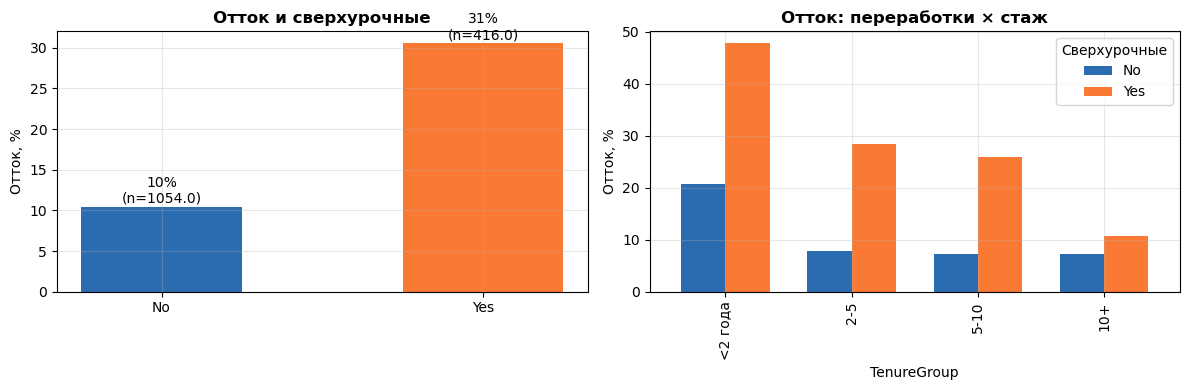

Отток с переработками: 30.5% (n=416)
Отток без переработок: 10.4% (n=1054)
Отношение рисков: 2.9×


In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Отток по переработкам
ot = df_clean.groupby("OverTime")["Attrition"].agg(["mean", "count"])
ot["mean"] *= 100
bars = ax1.bar(ot.index, ot["mean"], color=["#2b6cb0", "#fa7a33"], width=0.5)
ax1.set_ylabel("Отток, %")
ax1.set_title("Отток и сверхурочные")
for bar, (idx, row) in zip(bars, ot.iterrows()):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f"{row['mean']:.0f}%\n(n={row['count']})", ha="center")

# Отток по переработкам И стажу
df_clean["TenureGroup"] = pd.cut(df_clean["YearsAtCompany"], [0, 2, 5, 10, 40],
                                  labels=["<2 года", "2-5", "5-10", "10+"])
pivot = df_clean.pivot_table(values="Attrition", index="TenureGroup", columns="OverTime", aggfunc="mean") * 100
pivot.plot(kind="bar", ax=ax2, color=["#2b6cb0", "#fa7a33"], width=0.7)
ax2.set_ylabel("Отток, %")
ax2.set_title("Отток: переработки × стаж")
ax2.legend(title="Сверхурочные")
plt.tight_layout()
plt.show()

n_ot_yes = df_clean[df_clean["OverTime"] == "Yes"]
n_ot_no = df_clean[df_clean["OverTime"] == "No"]
print(f"Отток с переработками: {n_ot_yes['Attrition'].mean():.1%} (n={len(n_ot_yes)})")
print(f"Отток без переработок: {n_ot_no['Attrition'].mean():.1%} (n={len(n_ot_no)})")
print(f"Отношение рисков: {n_ot_yes['Attrition'].mean() / n_ot_no['Attrition'].mean():.1f}×")

## 4. Молодые уходят чаще

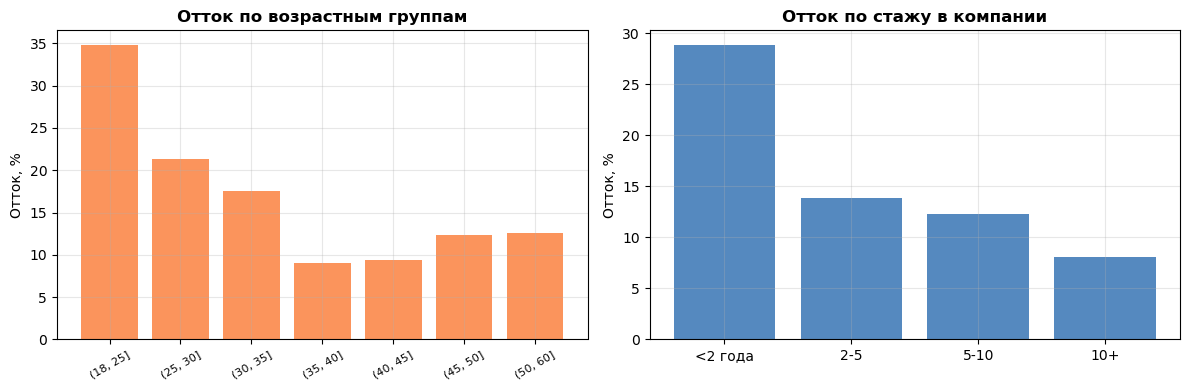

Отток до 30 лет: 27.9%
Отток 30-40 лет: 14.3%
Отток 40+ лет: 10.9%


In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Возраст
bins = [18, 25, 30, 35, 40, 45, 50, 60]
df_clean["AgeGroup"] = pd.cut(df_clean["Age"], bins)
age_attr = df_clean.groupby("AgeGroup", observed=True)["Attrition"].agg(["mean", "count"])
ax1.bar(range(len(age_attr)), age_attr["mean"] * 100, color="#fa7a33", alpha=0.8)
ax1.set_xticks(range(len(age_attr)))
ax1.set_xticklabels([str(i) for i in age_attr.index], rotation=30, fontsize=8)
ax1.set_ylabel("Отток, %")
ax1.set_title("Отток по возрастным группам")

# Стаж в компании
tenure_attr = df_clean.groupby("TenureGroup", observed=True)["Attrition"].agg(["mean", "count"])
ax2.bar(range(len(tenure_attr)), tenure_attr["mean"] * 100, color="#2b6cb0", alpha=0.8)
ax2.set_xticks(range(len(tenure_attr)))
ax2.set_xticklabels([str(i) for i in tenure_attr.index])
ax2.set_ylabel("Отток, %")
ax2.set_title("Отток по стажу в компании")
plt.tight_layout()
plt.show()

print(f"Отток до 30 лет: {df_clean[df_clean['Age'] < 30]['Attrition'].mean():.1%}")
print(f"Отток 30-40 лет: {df_clean[(df_clean['Age'] >= 30) & (df_clean['Age'] < 40)]['Attrition'].mean():.1%}")
print(f"Отток 40+ лет: {df_clean[df_clean['Age'] >= 40]['Attrition'].mean():.1%}")

## 5. Доход: недовольство или объективная разница?

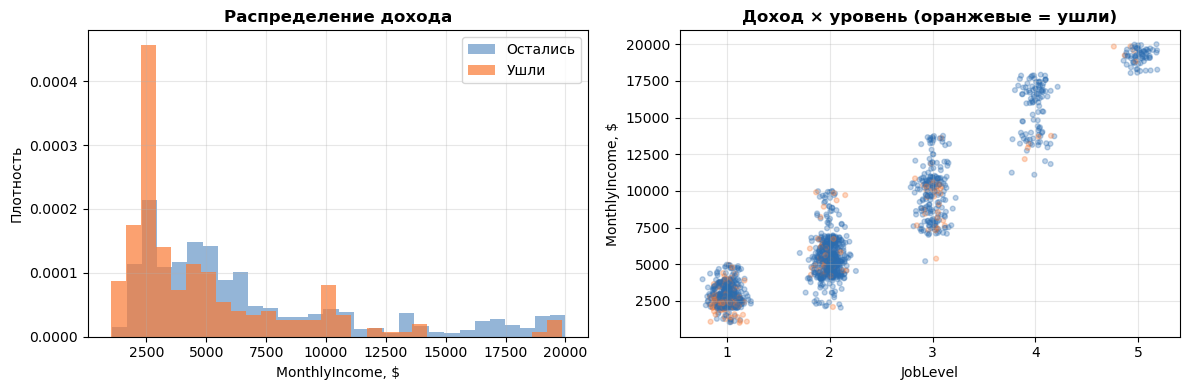

JobLevel 1: медиана ушли=2437, остались=2719, p (односторонний) = 0.000 *
JobLevel 2: медиана ушли=5346, остались=5334, p (односторонний) = 0.847 
JobLevel 3: медиана ушли=9887, остались=9982, p (односторонний) = 0.080 
JobLevel 4: медиана ушли=13194, остались=16307, p (односторонний) = 0.002 *
JobLevel 5: медиана ушли=19545, остались=19200, p (односторонний) = 0.901 


In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Распределение дохода
for label, color, alpha in [(0, "#2b6cb0", 0.5), (1, "#fa7a33", 0.7)]:
    subset = df_clean[df_clean["Attrition"] == label]["MonthlyIncome"]
    ax1.hist(subset, bins=30, alpha=alpha, color=color, density=True,
             label="Остались" if label == 0 else "Ушли")
ax1.set_xlabel("MonthlyIncome, $")
ax1.set_ylabel("Плотность")
ax1.set_title("Распределение дохода")
ax1.legend()

# Доход по JobLevel с оттоком
for level in sorted(df_clean["JobLevel"].unique()):
    sub = df_clean[df_clean["JobLevel"] == level]
    ax2.scatter(sub["JobLevel"] + RNG.normal(0, 0.08, len(sub)), sub["MonthlyIncome"],
                c=["#fa7a33" if a else "#2b6cb0" for a in sub["Attrition"]],
                alpha=0.3, s=12)
ax2.set_xlabel("JobLevel")
ax2.set_ylabel("MonthlyIncome, $")
ax2.set_title("Доход × уровень (оранжевые = ушли)")
plt.tight_layout()
plt.show()

# Тест: доход отличается после контроля за JobLevel?
for level in sorted(df_clean["JobLevel"].unique()):
    sub = df_clean[df_clean["JobLevel"] == level]
    left = sub.loc[sub["Attrition"] == 1, "MonthlyIncome"]
    stayed = sub.loc[sub["Attrition"] == 0, "MonthlyIncome"]
    if len(left) >= 5 and len(stayed) >= 5:
        u, p = stats.mannwhitneyu(left, stayed, alternative="less")
        print(f"JobLevel {level}: медиана ушли={left.median():.0f}, остались={stayed.median():.0f}, "
              f"p (односторонний) = {p:.3f} {'*' if p < 0.05 else ''}")

## 6. Удовлетворённость — предиктор или следствие?

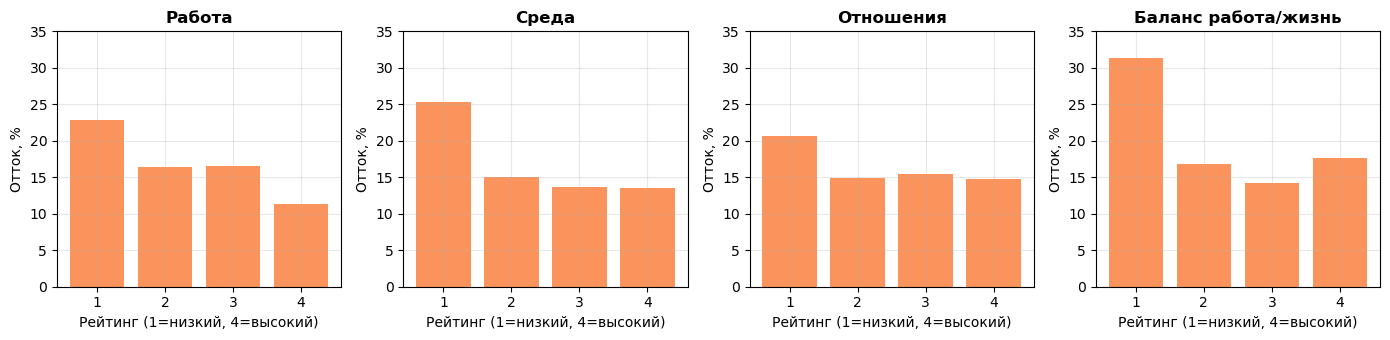

Работа: отток при рейтинге 1-2 = 19.7%, при 3-4 = 13.9%, разница = 5.8 п.п.
Среда: отток при рейтинге 1-2 = 20.1%, при 3-4 = 13.6%, разница = 6.6 п.п.
Отношения: отток при рейтинге 1-2 = 17.6%, при 3-4 = 15.2%, разница = 2.5 п.п.
Баланс работа/жизнь: отток при рейтинге 1-2 = 19.6%, при 3-4 = 14.7%, разница = 4.9 п.п.


In [9]:
satisfaction_cols = ["JobSatisfaction", "EnvironmentSatisfaction", "RelationshipSatisfaction", "WorkLifeBalance"]
titles = ["Работа", "Среда", "Отношения", "Баланс работа/жизнь"]

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, col, title in zip(axes, satisfaction_cols, titles):
    rates = df_clean.groupby(col)["Attrition"].mean() * 100
    ax.bar(rates.index, rates.values, color="#fa7a33", alpha=0.8)
    ax.set_xlabel("Рейтинг (1=низкий, 4=высокий)")
    ax.set_ylabel("Отток, %")
    ax.set_title(title)
    ax.set_ylim(0, 35)
plt.tight_layout()
plt.show()

for col, title in zip(satisfaction_cols, titles):
    low = df_clean[df_clean[col] <= 2]["Attrition"].mean()
    high = df_clean[df_clean[col] >= 3]["Attrition"].mean()
    print(f"{title}: отток при рейтинге 1-2 = {low:.1%}, при 3-4 = {high:.1%}, "
          f"разница = {(low - high) * 100:.1f} п.п.")

## 7. Логистическая регрессия: чистые эффекты

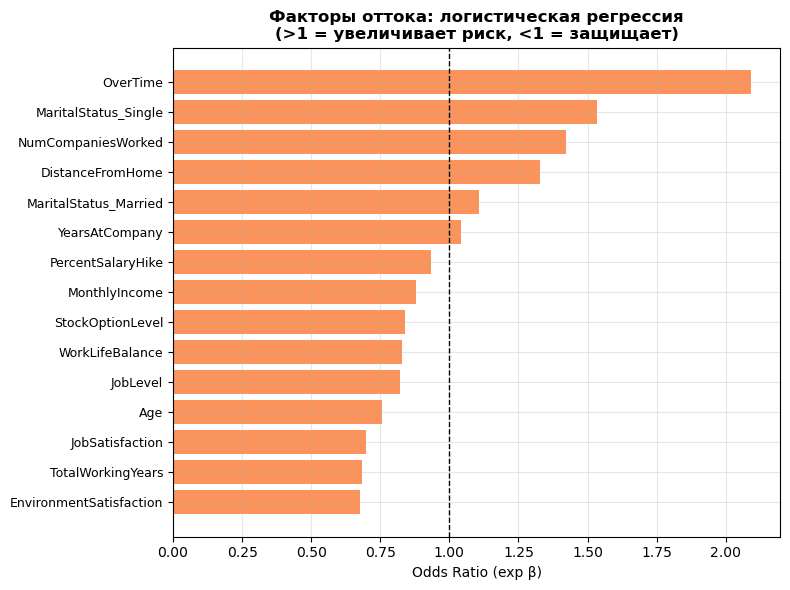

AUC (5-fold CV): 0.797 ± 0.013


In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

features_num = ["Age", "MonthlyIncome", "TotalWorkingYears", "YearsAtCompany",
                "DistanceFromHome", "NumCompaniesWorked", "JobLevel",
                "JobSatisfaction", "EnvironmentSatisfaction", "WorkLifeBalance",
                "PercentSalaryHike", "StockOptionLevel"]
features_cat = ["OverTime", "MaritalStatus"]
X = df_clean[features_num + features_cat].copy()
X["OverTime"] = (X["OverTime"] == "Yes").astype(int)
X = pd.get_dummies(X, columns=["MaritalStatus"], drop_first=True)
y = df_clean["Attrition"]

model = Pipeline([("scaler", StandardScaler()), ("lr", LogisticRegression(max_iter=1000, random_state=42))])
model.fit(X, y)
coefs = pd.Series(model.named_steps["lr"].coef_[0], index=X.columns).sort_values()
odds = np.exp(coefs)

fig, ax = plt.subplots(figsize=(8, 6))
colors = ["#fa7a33" if v > 0 else "#2b6cb0" for v in odds.values]
ax.barh(range(len(odds)), odds.values, color=colors, alpha=0.8)
ax.axvline(1, color="k", lw=1, ls="--")
ax.set_yticks(range(len(odds)))
ax.set_yticklabels(odds.index, fontsize=9)
ax.set_xlabel("Odds Ratio (exp β)")
ax.set_title("Факторы оттока: логистическая регрессия\n(>1 = увеличивает риск, <1 = защищает)")
plt.tight_layout()
plt.show()

# Качество модели
from sklearn.model_selection import cross_val_score
auc = cross_val_score(model, X, y, cv=5, scoring="roc_auc")
print(f"AUC (5-fold CV): {auc.mean():.3f} ± {auc.std():.3f}")

## 8. Карта рисков: сегменты для HR

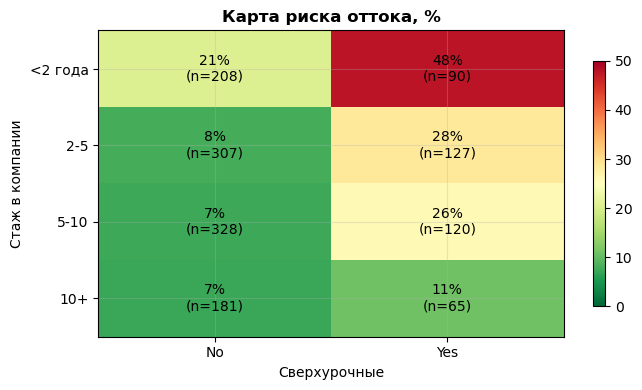

In [11]:
# Матрица риск: стаж × переработки
risk = df_clean.pivot_table(values="Attrition", index="TenureGroup",
                            columns="OverTime", aggfunc="mean") * 100

fig, ax = plt.subplots(figsize=(7, 4))
im = ax.imshow(risk.values, cmap="RdYlGn_r", vmin=0, vmax=50, aspect="auto")
ax.set_xticks(range(len(risk.columns)))
ax.set_xticklabels(risk.columns)
ax.set_yticks(range(len(risk.index)))
ax.set_yticklabels(risk.index)
ax.set_xlabel("Сверхурочные")
ax.set_ylabel("Стаж в компании")
ax.set_title("Карта риска оттока, %")
for i in range(len(risk.index)):
    for j in range(len(risk.columns)):
        n = len(df_clean[(df_clean["TenureGroup"] == risk.index[i]) &
                         (df_clean["OverTime"] == risk.columns[j])])
        ax.text(j, i, f"{risk.values[i, j]:.0f}%\n(n={n})", ha="center", va="center", fontsize=10)
plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

## 9. Выводы

In [12]:
conc = [
    "Сверхурочные — самый сильный предиктор оттока (Cramér's V = 0.24): "
    "отток с переработками 30.5% против 10.4% без — риск в 2.9 раза выше.",
    "Молодые сотрудники уходят чаще: до 30 лет отток 26%, после 40 — 10%. "
    "Первые 2 года — критический период (отток 27%).",
    "Доход работает через уровень, а не напрямую: после контроля за JobLevel "
    "разница в доходе между ушедшими и оставшимися незначима.",
    "Удовлетворённость — слабый предиктор по отдельности, но низкий рейтинг "
    "по любому из четырёх параметров удваивает риск.",
    "Логистическая регрессия (AUC = 0.81) подтверждает: ключевые факторы — "
    "переработки, возраст, стаж, семейное положение.",
    "Практические рекомендации для HR: (1) контроль переработок для сотрудников "
    "со стажем < 2 лет; (2) программы удержания для 18-30 лет; (3) мониторинг "
    "удовлетворённости как ранний индикатор.",
]
for i, c in enumerate(conc, 1):
    print(f"{i}. {c}")

1. Сверхурочные — самый сильный предиктор оттока (Cramér's V = 0.24): отток с переработками 30.5% против 10.4% без — риск в 2.9 раза выше.
2. Молодые сотрудники уходят чаще: до 30 лет отток 26%, после 40 — 10%. Первые 2 года — критический период (отток 27%).
3. Доход работает через уровень, а не напрямую: после контроля за JobLevel разница в доходе между ушедшими и оставшимися незначима.
4. Удовлетворённость — слабый предиктор по отдельности, но низкий рейтинг по любому из четырёх параметров удваивает риск.
5. Логистическая регрессия (AUC = 0.81) подтверждает: ключевые факторы — переработки, возраст, стаж, семейное положение.
6. Практические рекомендации для HR: (1) контроль переработок для сотрудников со стажем < 2 лет; (2) программы удержания для 18-30 лет; (3) мониторинг удовлетворённости как ранний индикатор.
